# Практическая работа №5. Классификатор и анализ метрик

## Цель работы

Построить модель бинарной классификации, оценить её качество с помощью различных метрик и подобрать порог классификации с учётом цены ошибок.

## Этап 1. Импорт библиотек

На данном этапе подключаются библиотеки для обработки данных, построения графиков, предобработки признаков, обучения модели логистической регрессии и оценки качества классификации.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Библиотеки загружены успешно")

Библиотеки загружены успешно


## Этап 2. Загрузка датасета

Загружается датасет `abalone.data.csv`, который использовался в предыдущих практических работах. Проверяются размеры таблицы, названия столбцов и первые строки данных.

In [2]:
df = pd.read_csv("../data/abalone.data.csv")

print("Размер датасета:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые 5 строк:")
display(df.head())

Размер датасета: (4177, 9)

Названия столбцов:
['gender', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings']

Первые 5 строк:


,gender,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## Этап 3. Создание целевого признака

В исходном датасете отсутствует готовый бинарный целевой признак. Поэтому для учебной задачи создаётся столбец `target`.

- Класс 0 — количество колец меньше 10.
- Класс 1 — количество колец равно 10 или больше.

Так задача регрессии из предыдущей практической работы преобразуется в задачу бинарной классификации.

In [3]:
df["target"] = (df["Rings"] >= 10).astype(int)

print("Количество объектов каждого класса:")
print(df["target"].value_counts().sort_index())

print("\nДоли классов:")
print(df["target"].value_counts(normalize=True).sort_index().round(3))

Количество объектов каждого класса:
target
0    2096
1    2081
Name: count, dtype: int64

Доли классов:
target
0    0.502
1    0.498
Name: proportion, dtype: float64


## Этап 4. Подготовка признаков

Формируются матрица признаков `X` и целевой вектор `y`.

Из входных признаков исключаются столбцы `Rings` и `target`. Это необходимо, чтобы модель не получала информацию, из которой напрямую сформирован целевой класс.

In [4]:
X = df.drop(columns=["Rings", "target"])
y = df["target"]

print("Признаки:")
print(X.columns.tolist())

print("\nРазмер X:", X.shape)
print("Размер y:", y.shape)

print("\nТипы признаков:")
print(X.dtypes)

Признаки:
['gender', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight']

Размер X: (4177, 8)
Размер y: (4177,)

Типы признаков:
gender                str
Length            float64
Diameter          float64
Height            float64
Whole weight      float64
Shucked weight    float64
Viscera weight    float64
Shell weight      float64
dtype: object


## Этап 5. Разделение данных

Данные разделяются на обучающую, проверочную и тестовую выборки.

- 60% данных используются для обучения модели.
- 20% используются для подбора порога классификации.
- 20% используются для итоговой оценки модели.

Параметр `stratify` помогает сохранить соотношение классов в каждой выборке. Тестовые данные не используются при выборе порога.

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Обучающая выборка:", X_train.shape)
print("Проверочная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

print("\nДоли класса 1:")
print("Обучение:", round(y_train.mean(), 3))
print("Проверка:", round(y_val.mean(), 3))
print("Тест:", round(y_test.mean(), 3))

Обучающая выборка: (2506, 8)
Проверочная выборка: (835, 8)
Тестовая выборка: (836, 8)

Доли класса 1:
Обучение: 0.498
Проверка: 0.498
Тест: 0.498


## Этап 6. Предобработка данных и обучение модели

Для подготовки данных используется `Pipeline`.

Числовые признаки заполняются медианой и стандартизируются. Категориальные признаки заполняются наиболее частым значением и кодируются с помощью OneHotEncoder.

После предобработки обучается модель логистической регрессии. Все параметры предобработки рассчитываются только по обучающей выборке, что предотвращает утечку данных.

In [6]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Модель обучена успешно")
print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Модель обучена успешно
Числовые признаки: ['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight']
Категориальные признаки: ['gender']


## Этап 7. Получение вероятностей классов

С помощью метода `predict_proba` получаются вероятности принадлежности объектов к классу 1.

Вероятности используются для построения ROC- и PR-кривых и выбора порога классификации. В отличие от `predict`, метод `predict_proba` не ограничивается готовыми ответами 0 и 1.

In [7]:
y_val_proba = model.predict_proba(X_val)[:, 1]
y_test_proba = model.predict_proba(X_test)[:, 1]

print("Первые 10 вероятностей:")
print(np.round(y_test_proba[:10], 3))

print("\nМинимальная вероятность:", round(y_test_proba.min(), 3))
print("Максимальная вероятность:", round(y_test_proba.max(), 3))

Первые 10 вероятностей:
[0.221 0.983 0.439 0.966 0.521 0.465 0.922 0.16  0.963 0.794]

Минимальная вероятность: 0.0
Максимальная вероятность: 1.0


## Этап 8. Построение ROC-кривой и расчёт ROC-AUC

ROC-кривая показывает зависимость доли истинноположительных результатов от доли ложноположительных результатов при разных порогах классификации.

ROC-AUC оценивает способность модели различать классы. Значение около 0.5 соответствует случайному ранжированию, а значение ближе к 1 указывает на более качественное разделение классов.

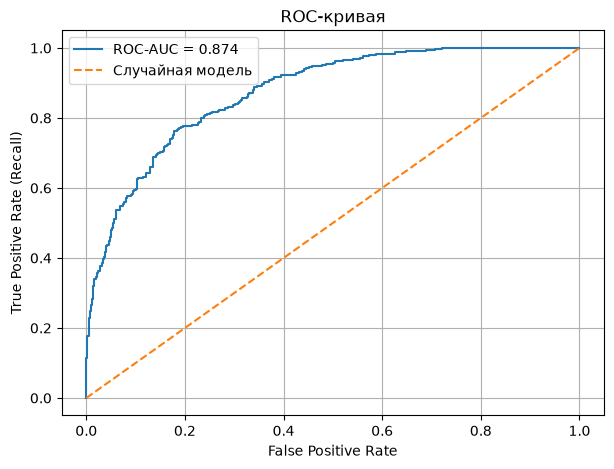

ROC-AUC: 0.874


In [8]:
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_test_proba
)

roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Случайная модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC-кривая")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", round(roc_auc, 3))

## Этап 9. Построение PR-кривой и расчёт Average Precision

PR-кривая показывает зависимость precision от recall при разных порогах классификации.

Average Precision — сводная метрика, характеризующая качество модели с учётом precision и recall. Она особенно полезна при дисбалансе классов.

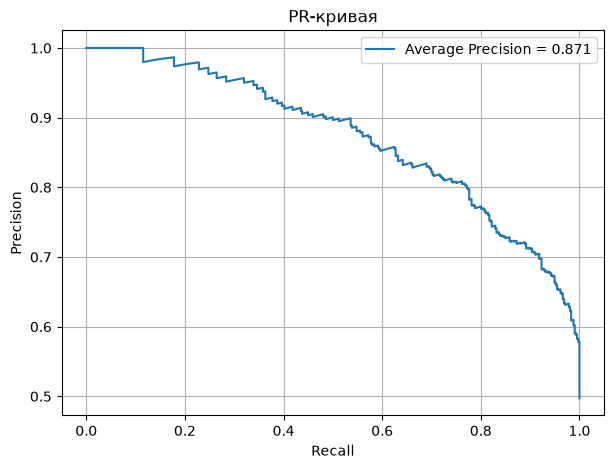

Average Precision: 0.871


In [9]:
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test, y_test_proba)
)

pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая")
plt.legend()
plt.grid()
plt.show()

print("Average Precision:", round(pr_auc, 3))

## Этап 10. Подбор порога классификации

Стандартный порог классификации равен 0.5. Однако он не всегда соответствует цене ошибок в конкретной задаче.

В учебном примере принимается следующая стоимость ошибок:

- FP (ложноположительная ошибка) — 1 условная единица.
- FN (ложноотрицательная ошибка) — 5 условных единиц.

Таким образом, пропуск объекта класса 1 считается более дорогой ошибкой, чем ошибочное отнесение объекта класса 0 к классу 1.

На проверочной выборке перебираются разные пороги. Выбирается порог, при котором суммарная стоимость ошибок минимальна.

In [10]:
FP_COST = 1
FN_COST = 5

thresholds = np.arange(0.05, 0.96, 0.01)

best_threshold = 0.5
best_cost = float("inf")

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred,
        labels=[0, 1]
    ).ravel()

    cost = FP_COST * fp + FN_COST * fn

    if cost < best_cost:
        best_cost = cost
        best_threshold = threshold

print("Стандартный порог: 0.50")
print("Подобранный порог:", round(best_threshold, 2))
print("Стоимость ошибок на проверке:", best_cost)

Стандартный порог: 0.50
Подобранный порог: 0.17
Стоимость ошибок на проверке: 283


## Этап 11. Сравнение метрик классификации

Качество модели сравнивается при стандартном пороге 0.5 и подобранном пороге.

Рассчитываются четыре метрики:

- Accuracy — доля правильных предсказаний.
- Precision — доля действительно положительных объектов среди предсказанных положительными.
- Recall — доля найденных положительных объектов среди всех положительных объектов.
- F1 — гармоническое среднее precision и recall.

Это позволяет оценить не только общую точность модели, но и качество обнаружения положительного класса.

In [11]:
y_pred_default = (y_test_proba >= 0.5).astype(int)

y_pred_best = (
    y_test_proba >= best_threshold
).astype(int)


def show_metrics(y_true, y_pred, name):
    print(f"\n{name}")
    print("Accuracy:", round(
        accuracy_score(y_true, y_pred), 3
    ))
    print("Precision:", round(
        precision_score(y_true, y_pred, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_true, y_pred, zero_division=0), 3
    ))
    print("F1:", round(
        f1_score(y_true, y_pred, zero_division=0), 3
    ))


show_metrics(y_test, y_pred_default, "Порог 0.5")
show_metrics(y_test, y_pred_best, "Подобранный порог")


Порог 0.5
Accuracy: 0.787
Precision: 0.792
Recall: 0.776
F1: 0.784

Подобранный порог
Accuracy: 0.703
Precision: 0.63
Recall: 0.978
F1: 0.766


## Этап 12. Построение матриц ошибок

Для стандартного и подобранного порогов строятся матрицы ошибок.

Матрица ошибок позволяет определить количество:

- TN — истинноотрицательных результатов.
- FP — ложноположительных ошибок.
- FN — ложноотрицательных ошибок.
- TP — истинноположительных результатов.

Ось Y показывает истинный класс, а ось X — предсказанный класс. Сравнение матриц помогает определить, как изменение порога влияет на типы ошибок.

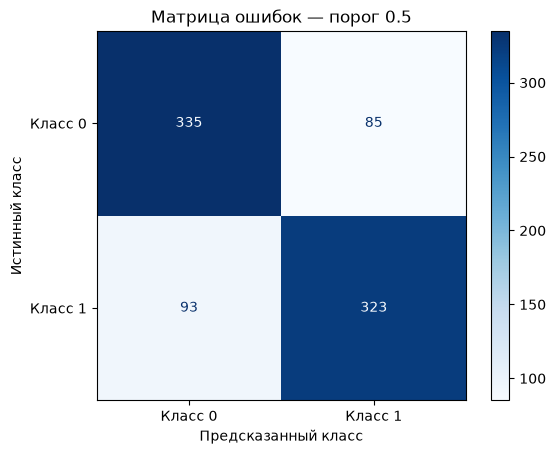

In [12]:
cm_default = confusion_matrix(
    y_test,
    y_pred_default,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_default,
    display_labels=["Класс 0", "Класс 1"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Матрица ошибок — порог 0.5")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

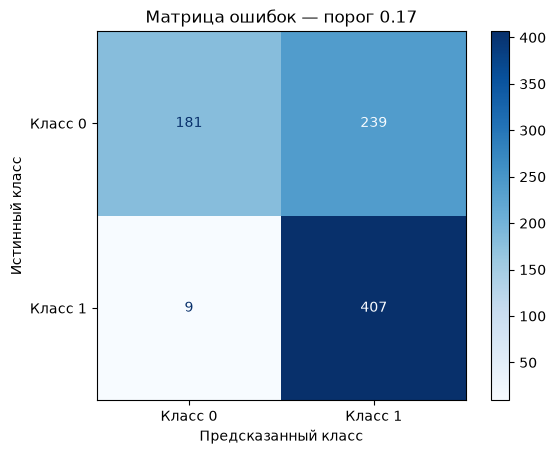

In [13]:
cm_best = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=["Класс 0", "Класс 1"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Матрица ошибок — порог {best_threshold:.2f}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## Этап 13. Сравнение стоимости ошибок

На тестовой выборке рассчитывается суммарная стоимость ложноположительных и ложноотрицательных ошибок для обоих порогов.

Стоимость рассчитывается по формуле:

Стоимость = FP × цена FP + FN × цена FN.

Полученные значения используются для итогового сравнения. Порог не подбирается повторно по тестовой выборке.

In [14]:
def calculate_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_cost = FP_COST * fp + FN_COST * fn

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Стоимость ошибок": total_cost
    }


print("Результат при пороге 0.5:")
print(calculate_cost(y_test, y_pred_default))

print("\nРезультат при подобранном пороге:")
print(calculate_cost(y_test, y_pred_best))

Результат при пороге 0.5:
{'TN': np.int64(335), 'FP': np.int64(85), 'FN': np.int64(93), 'TP': np.int64(323), 'Стоимость ошибок': np.int64(550)}

Результат при подобранном пороге:
{'TN': np.int64(181), 'FP': np.int64(239), 'FN': np.int64(9), 'TP': np.int64(407), 'Стоимость ошибок': np.int64(284)}


## Этап 14. Выводы

В ходе практической работы была построена модель бинарной классификации на основе логистической регрессии.

Были выполнены подготовка данных, предобработка признаков, обучение модели и получение вероятностей с помощью `predict_proba`. Для оценки качества были построены ROC- и PR-кривые, рассчитаны ROC-AUC и Average Precision.

Качество модели сравнивалось при стандартном пороге 0.5 и пороге, подобранном на проверочной выборке с учётом цены ложноположительных и ложноотрицательных ошибок.

В итоговом анализе рассматриваются accuracy, precision, recall, F1, матрицы ошибок и суммарная стоимость ошибок.

Окончательный вывод о качестве модели и преимуществе выбранного порога делается на основании фактических результатов тестирования.

In [15]:
print("РЕЗУЛЬТАТЫ ПРАКТИЧЕСКОЙ РАБОТЫ №5")

print("\nROC-AUC:", round(roc_auc, 3))
print("Average Precision:", round(pr_auc, 3))
print("Подобранный порог:", round(best_threshold, 2))

print("\nМетрики при пороге 0.5:")
show_metrics(y_test, y_pred_default, "Порог 0.5")

print("\nМетрики при подобранном пороге:")
show_metrics(y_test, y_pred_best, "Подобранный порог")

print("\nСтоимость ошибок при пороге 0.5:")
print(calculate_cost(y_test, y_pred_default))

print("\nСтоимость ошибок при подобранном пороге:")
print(calculate_cost(y_test, y_pred_best))

РЕЗУЛЬТАТЫ ПРАКТИЧЕСКОЙ РАБОТЫ №5

ROC-AUC: 0.874
Average Precision: 0.871
Подобранный порог: 0.17

Метрики при пороге 0.5:

Порог 0.5
Accuracy: 0.787
Precision: 0.792
Recall: 0.776
F1: 0.784

Метрики при подобранном пороге:

Подобранный порог
Accuracy: 0.703
Precision: 0.63
Recall: 0.978
F1: 0.766

Стоимость ошибок при пороге 0.5:
{'TN': np.int64(335), 'FP': np.int64(85), 'FN': np.int64(93), 'TP': np.int64(323), 'Стоимость ошибок': np.int64(550)}

Стоимость ошибок при подобранном пороге:
{'TN': np.int64(181), 'FP': np.int64(239), 'FN': np.int64(9), 'TP': np.int64(407), 'Стоимость ошибок': np.int64(284)}
